# Stage 2 supplementary material

S1–S3 are the unchanged Stage 1 supplement; this notebook produces S4 (Phase B: 85 sessions, 6 scanners). Requires bambi (`python_env` kernel).

In [1]:
import os
from pathlib import Path

import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import seaborn as sns

# Pipeline outputs (../pipeline/run_pipeline.sh): set RR_DERIV, or edit here
DERIV = Path(os.environ.get("RR_DERIV", "/path/to/derivatives"))
BRC = DERIV / "brc"
OUT = DERIV / "analysis" / "supplementary"
FIGS = DERIV / "analysis" / "figures" / "stage2"
TRACES = OUT / "traces"
TRACES.mkdir(parents=True, exist_ok=True)
CONDITIONS = ["non-denoised", "denoised"]
ARM_DIR = {"non-denoised": "nondenoised", "denoised": "denoised"}
sessions = sorted(p.name for p in (BRC / "nondenoised").glob("sub-*_ses-*"))
print(len(sessions), "sessions")
plt.rcParams["figure.dpi"] = 70
sns.set_theme(style="whitegrid")


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIGS / f"{name}.{ext}", dpi=300 if ext == "png" else None, bbox_inches="tight")


def fit_all(df, metrics, **fit_kwargs):
    """Fit metric ~ condition + (1|scan_id) per metric; returns the traces and a summary table."""
    df = df.copy()
    df["condition"] = pd.Categorical(df["condition"], categories=CONDITIONS, ordered=True)
    df["scan_id"] = df["scan_id"].astype("category")
    traces, rows = {}, []
    for m in metrics:
        nc = TRACES / f"{m}.nc"   # cached posterior: delete the file to refit
        if nc.is_file():
            trace = az.from_netcdf(nc)
        else:
            trace = bmb.Model(f"{m} ~ condition + (1|scan_id)", data=df).fit(progressbar=False, **fit_kwargs)
            trace.to_netcdf(nc)
        traces[m] = trace
        s = az.summary(trace, var_names=["condition"], hdi_prob=0.95).iloc[0]
        rhat = az.rhat(trace)
        rows.append(dict(metric=m, mean_non_denoised=df.loc[df.condition == "non-denoised", m].mean(),
                         effect_denoised=s["mean"], hdi_low=s["hdi_2.5%"], hdi_high=s["hdi_97.5%"],
                         effect_pct=100 * s["mean"] / df.loc[df.condition == "non-denoised", m].mean(),
                         p_effect_lt0=float((trace.posterior["condition"].values < 0).mean()),
                         rhat_effect=s["r_hat"], ess_bulk_effect=s["ess_bulk"], ess_tail_effect=s["ess_tail"],
                         max_rhat_all=float(max(rhat[v].max() for v in rhat.data_vars)),
                         divergences=int(trace.sample_stats["diverging"].sum())))
    return traces, pd.DataFrame(rows)


def metrics_figure(df, metrics, traces, unit, swarm=False):
    """Row 1: values per arm (violins); row 2: posterior of the denoising effect with its 95% HDI.
    unit: dict metric -> axis unit."""
    fig, axes = plt.subplots(2, len(metrics), figsize=(4.2 * len(metrics), 7))
    for j, (m, title) in enumerate(metrics.items()):
        ax = axes[0, j]
        sns.violinplot(data=df, x="condition", y=m, order=CONDITIONS, inner="quartile", cut=0, ax=ax)
        if swarm:
            sns.swarmplot(data=df, x="condition", y=m, order=CONDITIONS, color="black", alpha=0.5, size=3, ax=ax)
        ax.set_title(title, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel(unit[m])
        ax = axes[1, j]
        post = traces[m].posterior["condition"].values.ravel()
        lo, hi = az.hdi(post, hdi_prob=0.95)
        sns.kdeplot(post, ax=ax, color="C0", fill=True, alpha=0.3)
        ax.plot([lo, hi], [0, 0], color="k", lw=4, solid_capstyle="butt")
        ax.axvline(0, color="k", ls="--", lw=1)
        ax.set_title(f"mean {post.mean():.2g}, 95% HDI [{lo:.2g}, {hi:.2g}]", fontsize=10)
        ax.set_yticks([]); ax.set_ylabel(""); ax.set_xlabel(f"effect of denoising ({unit[m]})")
        ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    fig.tight_layout()
    return fig


85 sessions


## S4.1 Head motion and data quality (EDDY QC, non-denoised)

Median [min–max] per scanner.

In [2]:
qc = pd.read_csv(DERIV / "qc" / "eddy_qc_nondenoised.csv")
qc["scan_id"] = qc.subject + "_" + qc.session
QC = {"mot_abs_mean_mm": "Absolute motion (mm)", "mot_rel_mean_mm": "Relative motion (mm)",
      "snr_b0": "SNR b0", "cnr_b1000": "CNR b1000", "cnr_b2000": "CNR b2000"}


def med_range(x, nd=2):
    return f"{x.median():.{nd}f} [{x.min():.{nd}f}–{x.max():.{nd}f}]"


def qc_row(g):
    return {"Sessions": len(g), **{v: med_range(g[k]) for k, v in QC.items()}}


def qc_table(d):
    rows = {s: qc_row(g) for s, g in d.groupby("scanner_label")}
    rows["All"] = qc_row(d)
    return pd.DataFrame.from_dict(rows, orient="index")


table_qc = qc_table(qc)
table_qc.to_csv(OUT / "eddy_qc_by_scanner.csv")
print(len(qc), "sessions;", (qc["flags"].fillna("") != "").sum(), "flagged for review (none excluded)")
table_qc

85 sessions; 18 flagged for review (none excluded)


,Sessions,Absolute motion (mm),Relative motion (mm),SNR b0,CNR b1000,CNR b2000
Achieva32_SPMICUP,10,1.00 [0.44–4.53],0.28 [0.17–0.48],17.92 [16.77–20.98],1.26 [1.16–1.40],1.52 [1.28–1.64]
Ingenia32_SPMICUP,15,0.57 [0.38–0.95],0.36 [0.24–0.80],15.46 [13.85–18.11],0.93 [0.78–1.22],0.97 [0.81–1.27]
Premier21_OCMR,15,0.68 [0.31–1.47],0.25 [0.19–0.31],20.07 [17.53–21.56],1.07 [0.89–1.37],1.23 [0.97–1.69]
Premier48_SPMICQMC,15,0.52 [0.34–0.78],0.22 [0.15–0.27],20.84 [16.12–23.34],1.13 [0.92–1.35],1.32 [1.08–1.51]
Prisma32_FMRIB,15,0.40 [0.22–0.56],0.24 [0.22–0.30],24.59 [21.41–26.75],1.75 [1.45–2.19],1.87 [1.71–2.61]
Prisma64_OHBA,15,0.61 [0.28–1.55],0.69 [0.20–0.80],23.35 [19.33–24.91],1.53 [1.16–1.92],1.90 [1.23–2.23]
All,85,0.56 [0.22–4.53],0.26 [0.15–0.80],20.61 [13.85–26.75],1.20 [0.78–2.19],1.36 [0.81–2.61]


Absolute motion vs UK Biobank ([field 24450](https://biobank.ndph.ox.ac.uk/showcase/field.cgi?id=24450), all instances; Alfaro-Almagro et al., 2018). Descriptive: our sessions come from 10 participants.

In [3]:
UKB = dict(mean=1.09269, sd=0.469415, median=0.981477)  # Showcase field 24450, all instances
x = qc.mot_abs_mean_mm
table_ukb = pd.DataFrame({"This study (85 sessions)": [x.mean(), x.std(), x.median()],
                          "UK Biobank": list(UKB.values())}, index=["mean", "SD", "median"]).round(2)
table_ukb.to_csv(OUT / "motion_vs_ukbiobank.csv")
table_ukb

,This study (85 sessions),UK Biobank
mean,0.70,1.09
SD,0.54,0.47
median,0.56,0.98


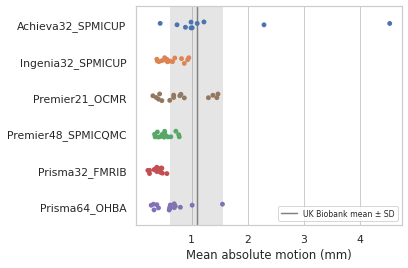

In [4]:
order = sorted(qc.scanner_label.unique())
fig, ax = plt.subplots(figsize=(6, 4))
sns.stripplot(data=qc, y="scanner_label", x="mot_abs_mean_mm", hue="scanner_label", order=order, size=5, legend=False, ax=ax)
ax.axvspan(UKB["mean"] - UKB["sd"], UKB["mean"] + UKB["sd"], color="grey", alpha=0.2, lw=0)
ax.axvline(UKB["mean"], color="grey", lw=1.5, label="UK Biobank mean ± SD")
ax.set_xlabel("Mean absolute motion (mm)"); ax.set_ylabel(""); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); save(fig, "FigS_motion_ukbiobank"); plt.show()

## S4.2 Effect of denoising on TOPUP and EDDY

Stage 1 analysis on the full cohort: `metric ~ condition + (1|scan_id)` per metric.

### TOPUP field (Hz, within the brain)

In [5]:
if (OUT / "topup_field_metrics.csv").is_file():   # cached: delete the CSV to re-read the images
    field = pd.read_csv(OUT / "topup_field_metrics.csv")
else:
    rows = []
    for scan_id in sessions:
        mask = nib.load(str(BRC / "nondenoised" / scan_id / "analysis/dMRI/preproc/topup/nodif_brain_mask.nii.gz")).get_fdata() > 0
        for cond in CONDITIONS:
            f = nib.load(str(BRC / ARM_DIR[cond] / scan_id / "analysis/dMRI/preproc/topup/myfield.nii.gz")).get_fdata()
            v = f[mask]
            sub, ses = scan_id.split("_", 1)
            rows.append(dict(subject=sub, session=ses, scan_id=scan_id, condition=cond, mean_abs_field=np.abs(v).mean(),
                             median_abs_field=np.median(np.abs(v)), std_field=v.std(),
                             p95_abs_field=np.percentile(np.abs(v), 95), n_voxels=int(mask.sum())))
    field = pd.DataFrame(rows)
    field.to_csv(OUT / "topup_field_metrics.csv", index=False)
FIELD = {"mean_abs_field": "Mean |field|", "median_abs_field": "Median |field|", "std_field": "SD of field",
         "p95_abs_field": "95th percentile |field|"}
field.groupby("condition")[list(FIELD)].describe().T.round(2)

condition               denoised  non-denoised
mean_abs_field   count     85.00         85.00
                 mean      21.28         21.27
                 std        7.67          7.66
                 min       10.52         10.53
                 25%       15.77         15.78
                 50%       19.14         19.15
                 75%       25.25         25.28
                 max       46.65         46.59
median_abs_field count     85.00         85.00
                 mean      14.68         14.67
                 std        7.39          7.36
                 min        5.86          5.87
                 25%        9.03          9.02
                 50%       12.61         12.61
                 75%       17.67         17.66
                 max       40.81         40.71
std_field        count     85.00         85.00
                 mean      29.82         29.82
                 std        8.66          8.66
                 min       16.13         16.15
                 25%       23.23         23.23
                 50%       27.21         27.19
                 75%       35.41         35.40
                 max       57.59         57.57
p95_abs_field    count     85.00         85.00
                 mean      64.85         64.86
                 std       18.16         18.17
                 min       35.46         35.47
                 25%       50.43         50.43
                 50%       63.25         63.27
                 75%       77.77         77.89
                 max      112.59        112.58

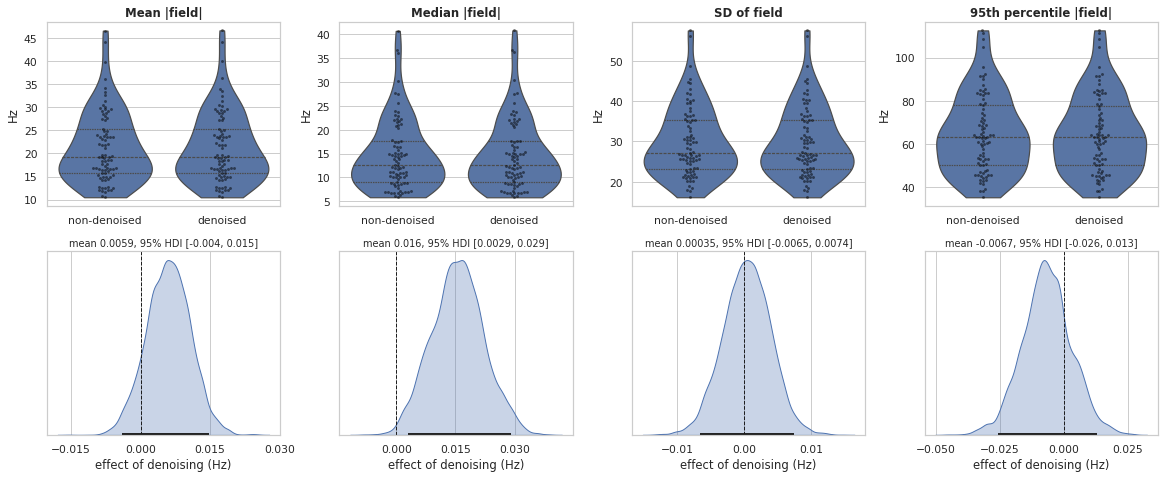

,metric,mean_non_denoised,effect_denoised,hdi_low,hdi_high,effect_pct,p_effect_lt0,rhat_effect,ess_bulk_effect,ess_tail_effect,max_rhat_all,divergences
0,mean_abs_field,21.2701,0.006,-0.004,0.015,0.0282,0.1067,1.00,954.0,1383.0,1.1486,34
1,median_abs_field,14.6683,0.016,0.003,0.029,0.1091,0.0056,1.00,1085.0,1326.0,1.1837,0
2,std_field,29.8207,0.000,-0.007,0.007,0.0000,0.4549,1.01,1021.0,1881.0,1.2278,0
3,p95_abs_field,64.8595,-0.007,-0.026,0.013,-0.0108,0.7719,1.01,470.0,793.0,1.1340,0


In [6]:
field_traces, field_res = fit_all(field, FIELD, draws=4000, tune=2000, chains=4, cores=4, random_seed=42,
                                  nuts={"max_treedepth": 15, "target_accept": 0.99})
fig = metrics_figure(field, FIELD, field_traces, dict.fromkeys(FIELD, "Hz"), swarm=True); save(fig, "FigS_topup"); plt.show()
field_res.round(4)

Session intercepts did not converge (R-hat > 1.01), so the paired comparison (denoised − non-denoised per session, 95% t-interval) is also reported.

In [7]:
from scipy import stats

w = field.pivot(index="scan_id", columns="condition", values=list(FIELD))
rows = []
for m in FIELD:
    d = (w[m]["denoised"] - w[m]["non-denoised"]).to_numpy()
    lo, hi = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
    rows.append(dict(metric=m, sessions=len(d), mean_diff=d.mean(), ci_low=lo, ci_high=hi,
                     pct_of_mean=100 * d.mean() / w[m]["non-denoised"].mean(), median_diff=np.median(d),
                     min_diff=d.min(), max_diff=d.max()))
field_paired = pd.DataFrame(rows)
field_paired.to_csv(OUT / "topup_paired.csv", index=False)
field_paired.round(4)

,metric,sessions,mean_diff,ci_low,ci_high,pct_of_mean,median_diff,min_diff,max_diff
0,mean_abs_field,85,0.0060,-0.0036,0.0156,0.0281,-0.0022,-0.0944,0.1348
1,median_abs_field,85,0.0161,0.0033,0.0289,0.1095,0.0019,-0.1054,0.2140
2,std_field,85,0.0002,-0.0072,0.0076,0.0007,-0.0002,-0.1084,0.1016
3,p95_abs_field,85,-0.0074,-0.0271,0.0123,-0.0114,-0.0053,-0.2664,0.3037


### EDDY (per volume)

In [8]:
if (OUT / "eddy_metrics.csv").is_file():   # cached: delete the CSV to re-read the images
    eddy = pd.read_csv(OUT / "eddy_metrics.csv")
else:
    rows = []
    for scan_id in sessions:
        sub, ses = scan_id.split("_", 1)
        for cond in CONDITIONS:
            e = BRC / ARM_DIR[cond] / scan_id / "analysis/dMRI/preproc/eddy"
            rms = np.atleast_2d(np.loadtxt(e / "eddy_unwarped_images.eddy_movement_rms"))
            par = np.atleast_2d(np.loadtxt(e / "eddy_unwarped_images.eddy_parameters"))
            rows.append(pd.DataFrame(dict(volume=np.arange(len(rms)), abs_rms=rms[:, 0], ec_linear_x=par[:, 6],
                                          ec_linear_y=par[:, 7], ec_linear_z=par[:, 8], subject=sub, session=ses,
                                          scan_id=scan_id, condition=cond)))
    eddy = pd.concat(rows, ignore_index=True)
    eddy.to_csv(OUT / "eddy_metrics.csv", index=False)
EDDY = {"abs_rms": "RMS motion", "ec_linear_x": "Linear eddy current, x", "ec_linear_y": "Linear eddy current, y",
        "ec_linear_z": "Linear eddy current, z"}
print(len(eddy), "volumes;", eddy.groupby("condition").size().to_dict())
eddy.groupby("condition")[list(EDDY)].describe().T.round(4)

18120 volumes; {'denoised': 9060, 'non-denoised': 9060}


condition           denoised  non-denoised
abs_rms     count  9060.0000     9060.0000
            mean      0.6475        0.6969
            std       0.6324        0.6373
            min       0.0000        0.0000
            25%       0.3241        0.3617
            50%       0.4672        0.5272
            75%       0.7128        0.7883
            max       5.2618        5.2840
ec_linear_x count  9060.0000     9060.0000
            mean      0.0010        0.0010
            std       0.0442        0.0490
            min      -0.1496       -0.1790
            25%      -0.0282       -0.0306
            50%       0.0000        0.0000
            75%       0.0305        0.0327
            max       0.1446        0.1657
ec_linear_y count  9060.0000     9060.0000
            mean      0.0000       -0.0011
            std       0.0463        0.0496
            min      -0.2635       -0.2754
            25%      -0.0243       -0.0263
            50%       0.0000        0.0000
            75%       0.0273        0.0276
            max       0.2473        0.2603
ec_linear_z count  9060.0000     9060.0000
            mean      0.0025        0.0033
            std       0.0465        0.0500
            min      -0.2120       -0.2164
            25%      -0.0226       -0.0238
            50%       0.0003        0.0002
            75%       0.0285        0.0311
            max       0.3470        0.3555

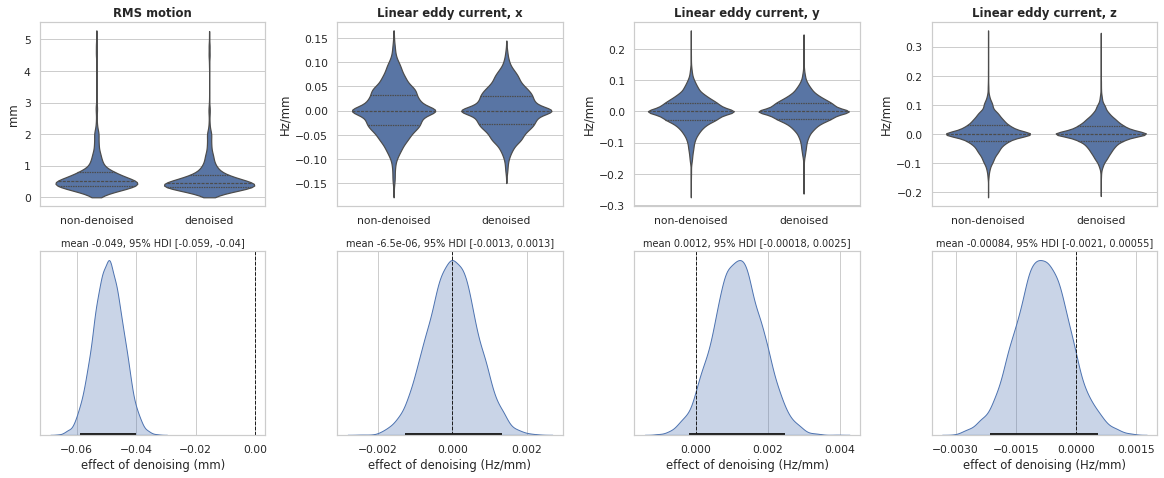

,metric,mean_non_denoised,effect_denoised,hdi_low,hdi_high,effect_pct,p_effect_lt0,rhat_effect,ess_bulk_effect,ess_tail_effect,max_rhat_all,divergences
0,abs_rms,0.69688,-0.049,-0.059,-0.040,-7.03138,1.00000,1.0,3330.0,4598.0,1.10382,0
1,ec_linear_x,0.00104,-0.000,-0.001,0.001,-0.00000,0.50113,1.0,15212.0,6036.0,1.00229,0
2,ec_linear_y,-0.00113,0.001,-0.000,0.002,-88.79007,0.04212,1.0,8682.0,5237.0,1.00374,0
3,ec_linear_z,0.00329,-0.001,-0.002,0.001,-30.38712,0.89662,1.0,10663.0,5515.0,1.00293,0


In [9]:
eddy_traces, eddy_res = fit_all(eddy, EDDY, draws=2000, tune=1000, chains=4, cores=4, random_seed=42,
                                target_accept=0.99)
fig = metrics_figure(eddy, EDDY, eddy_traces, {"abs_rms": "mm", "ec_linear_x": "Hz/mm", "ec_linear_y": "Hz/mm", "ec_linear_z": "Hz/mm"}); save(fig, "FigS_eddy"); plt.show()
eddy_res.round(5)

### Summary

In [10]:
summary = pd.concat([field_res.assign(correction="TOPUP"), eddy_res.assign(correction="EDDY")])
summary.to_csv(OUT / "summary.csv", index=False)
summary[["correction", "metric", "mean_non_denoised", "effect_denoised", "hdi_low", "hdi_high", "effect_pct",
         "rhat_effect", "ess_bulk_effect", "max_rhat_all", "divergences"]].round(4)

,correction,metric,mean_non_denoised,effect_denoised,hdi_low,hdi_high,effect_pct,rhat_effect,ess_bulk_effect,max_rhat_all,divergences
0,TOPUP,mean_abs_field,21.2701,0.006,-0.004,0.015,0.0282,1.00,954.0,1.1486,34
1,TOPUP,median_abs_field,14.6683,0.016,0.003,0.029,0.1091,1.00,1085.0,1.1837,0
2,TOPUP,std_field,29.8207,0.000,-0.007,0.007,0.0000,1.01,1021.0,1.2278,0
3,TOPUP,p95_abs_field,64.8595,-0.007,-0.026,0.013,-0.0108,1.01,470.0,1.1340,0
0,EDDY,abs_rms,0.6969,-0.049,-0.059,-0.040,-7.0314,1.00,3330.0,1.1038,0
1,EDDY,ec_linear_x,0.0010,-0.000,-0.001,0.001,-0.0000,1.00,15212.0,1.0023,0
2,EDDY,ec_linear_y,-0.0011,0.001,-0.000,0.002,-88.7901,1.00,8682.0,1.0037,0
3,EDDY,ec_linear_z,0.0033,-0.001,-0.002,0.001,-30.3871,1.00,10663.0,1.0029,0
